In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

stat_path = Path('../data/processed/GSE114273 (siPARP1_siPARP2)')

In [13]:
# UTR annotation data with 8mer motif

UTR_path = Path(
    '/home/piets/sirna_shrna_offtargets/data/processed/GSE114273 (siPARP1_siPARP2)/GSE114273_expression_data_8mer_A1_annotated.tsv'
)

utr_df = pd.read_csv(UTR_path, sep="\t")

print(utr_df.shape)
display(utr_df.head())

(19227, 21)


,GeneID,EnsemblGeneID,siNC_rep1,siNC_rep2,siPARP1-A_rep1,siPARP1-A_rep2,siPARP1-B_rep1,siPARP1-B_rep2,siPARP2-A_rep1,siPARP2-A_rep2,...,siPARP2-B_rep2,n_utr_transcripts,siPARP1A_target_8mer_A1_present,siPARP1A_target_8mer_A1_count,siPARP1B_target_8mer_A1_present,siPARP1B_target_8mer_A1_count,siPARP2A_target_8mer_A1_present,siPARP2A_target_8mer_A1_count,siPARP2B_target_8mer_A1_present,siPARP2B_target_8mer_A1_count
0,79501,ENSG00000186092,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.00000,1.0,False,0.0,False,0.0,False,0.0,False,0.0
1,729759,ENSG00000284733,0.00000,0.00000,0.11700,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,81399,ENSG00000284662,0.01957,0.03683,0.03803,0.02007,0.02057,0.02181,0.03558,0.03497,...,0.03697,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,148398,ENSG00000187634,21.28000,23.77000,17.28000,15.92000,25.34000,24.84000,20.35000,18.93000,...,15.33000,1.0,False,0.0,False,0.0,False,0.0,False,0.0
4,26155,ENSG00000188976,98.92000,111.50000,112.20000,109.70000,111.50000,101.90000,147.10000,139.00000,...,130.80000,1.0,False,0.0,False,0.0,False,0.0,False,0.0


In [10]:
# Load and inspect stat results

stat_path = Path('../data/processed/GSE114273 (siPARP1_siPARP2)')

stat_results = {}

for treatment in [
    "siPARP1-A",
    "siPARP1-B",
    "siPARP2-A",
    "siPARP2-B"
]:
    stat_results[treatment] = pd.read_csv(
        stat_path / f"GSE114273_{treatment}_DGE_results.tsv",
        sep="\t",
        index_col=0
    )


for treatment, results in stat_results.items():
    print(f"{treatment}: {results.shape}"),
    print(f"(treatment): {results.head()}")

siPARP1-A: (19227, 6)
(treatment):                     baseMean  log2FoldChange     lfcSE      stat    pvalue  \
EnsemblGeneID                                                                
ENSG00000186092     0.000000             NaN       NaN       NaN       NaN   
ENSG00000284733     0.192443        1.476045  5.345056  0.276151  0.782432   
ENSG00000284662     1.466398        0.053289  1.747147  0.030501  0.975668   
ENSG00000187634   447.519945       -0.435754  0.119166 -3.656705  0.000255   
ENSG00000188976  2918.659251        0.080683  0.069533  1.160357  0.245903   

                     padj  
EnsemblGeneID              
ENSG00000186092       NaN  
ENSG00000284733       NaN  
ENSG00000284662       NaN  
ENSG00000187634  0.000951  
ENSG00000188976  0.371888  
siPARP1-B: (19227, 6)
(treatment):                     baseMean  log2FoldChange     lfcSE      stat    pvalue  \
EnsemblGeneID                                                                
ENSG00000186092     0.000000   

In [ ]:
# verify ensembl ID consistency

for treatment, results in stat_results.items():

    common_genes = utr_df["EnsemblGeneID"].isin(
        results.index
    ).sum()

    print(f"{treatment}:")
    print(f"  Matching genes: {common_genes}")
    print(f"  Genes in expression dataframe: {len(utr_df)}")
    print(f"  Genes in DGE results: {len(results)}")

siPARP1-A:
  Matching genes: 19227
  Genes in expression dataframe: 19227
  Genes in DGE results: 19227
siPARP1-B:
  Matching genes: 19227
  Genes in expression dataframe: 19227
  Genes in DGE results: 19227
siPARP2-A:
  Matching genes: 19227
  Genes in expression dataframe: 19227
  Genes in DGE results: 19227
siPARP2-B:
  Matching genes: 19227
  Genes in expression dataframe: 19227
  Genes in DGE results: 19227


In [ ]:
# Merge gene expression_seed annotation with DGE results

sirna_analysis = {}

for treatment, results in stat_results.items():

    # Merge gene-level annotation with DGE results
    merged = utr_df.merge(
        results,
        left_on="EnsemblGeneID",
        right_index=True,
        how="inner"
    )

    # Retain genes with annotated UTRs and valid log2FC
    merged = merged.dropna(
        subset=["n_utr_transcripts", "log2FoldChange"]
    ).copy()

    sirna_analysis[treatment] = merged

In [24]:
# Save sirna_analysis per treatment

for treatment, df in sirna_analysis.items():

    filename = f"GSE114273_{treatment}_seed_analysis_input.tsv"

    df.to_csv(
        stat_path / filename,
        sep="\t",
        index=False
    )

In [ ]:
# Validate seed-matching populations

for treatment, df in sirna_analysis.items():

    seed_column = f"{treatment.replace('-', '')}_target_8mer_A1_present"

    seed_positive = df[seed_column].eq(True).sum()
    seed_negative = df[seed_column].eq(False).sum()

    print(f"\n{treatment}")
    print("Total genes:", len(df))
    print("Seed-positive:", seed_positive)
    print("Seed-negative:", seed_negative)


siPARP1-A
Total genes: 16638
Seed-positive: 871
Seed-negative: 15767

siPARP1-B
Total genes: 16638
Seed-positive: 736
Seed-negative: 15902

siPARP2-A
Total genes: 16638
Seed-positive: 658
Seed-negative: 15980

siPARP2-B
Total genes: 16638
Seed-positive: 788
Seed-negative: 15850


#### Validations is consistent with previous observations:

- Expressed protein-coding genes	19,227
- Genes with mapped 3′UTRs	18,268
- Genes without mapped 3′UTRs	959

- Genes with valid log2FC	17,240
- Genes without valid log2FC	1,987

- Overlap, genes without mapped 3'UTR and valid log2FC  357

- Analysis population = 19,227-959-1,987+357 = 16,638 

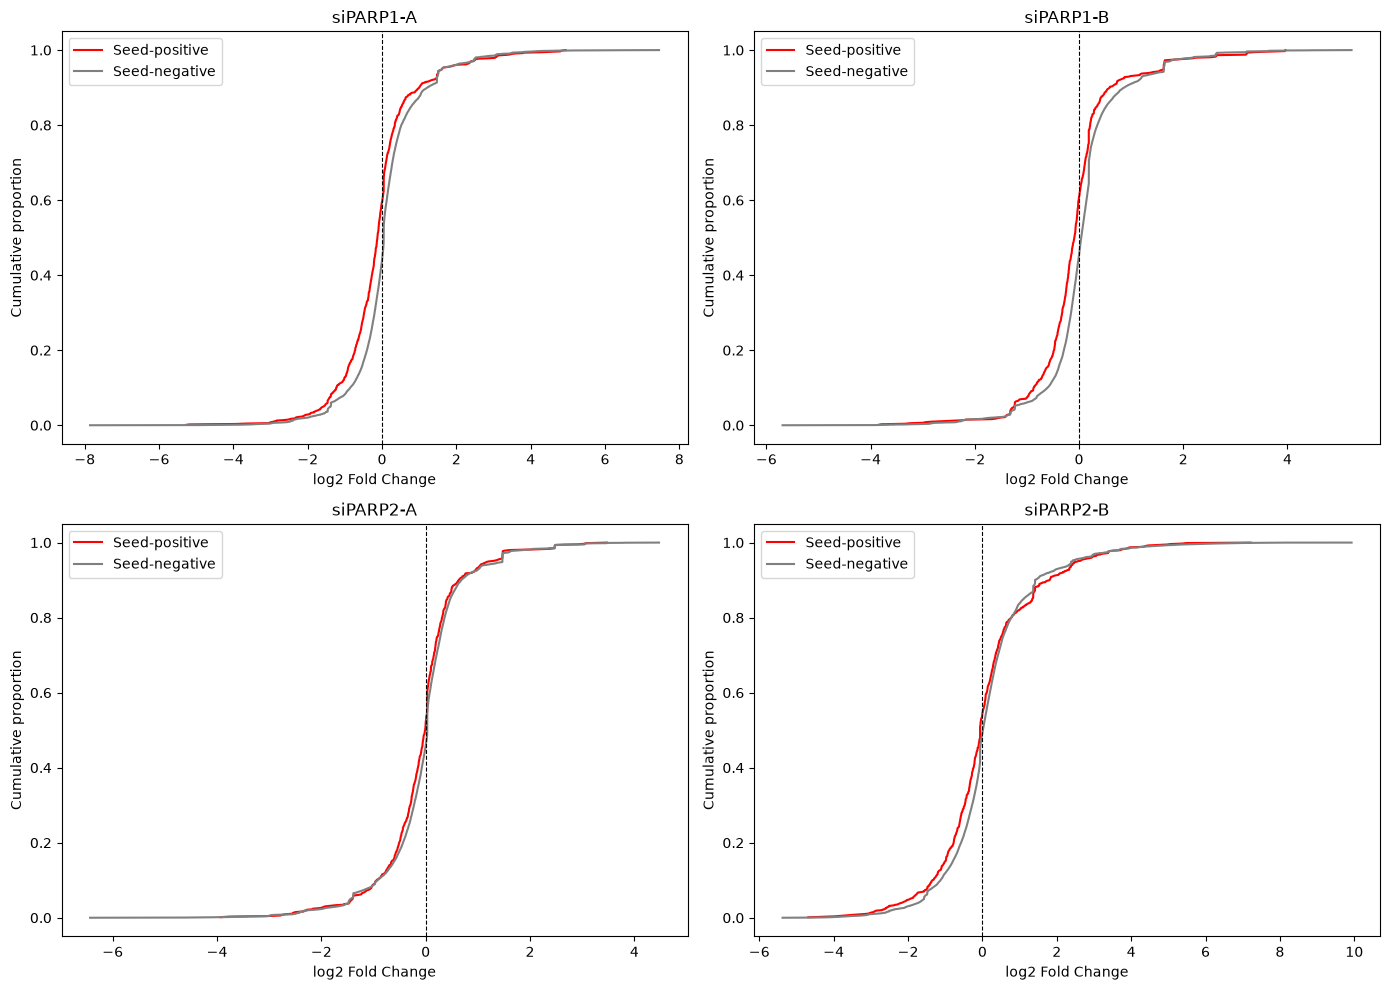

In [25]:
# Generate CDF plots

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (treatment, df) in zip(axes, sirna_analysis.items()):

    seed_column = f"{treatment.replace('-', '')}_target_8mer_A1_present"

    # Separate the two populations
    positive = df.loc[
        df[seed_column].eq(True), "log2FoldChange"
    ].sort_values()

    negative = df.loc[
        df[seed_column].eq(False), "log2FoldChange"
    ].sort_values()

    # Calculate cumulative proportions
    positive_cdf = np.arange(1, len(positive) + 1) / len(positive)
    negative_cdf = np.arange(1, len(negative) + 1) / len(negative)

    # Plot
    ax.plot(positive, positive_cdf, label="Seed-positive", color="red")
    ax.plot(negative, negative_cdf, label="Seed-negative", color="grey")

    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)

    ax.set_title(treatment)
    ax.set_xlabel("log2 Fold Change")
    ax.set_ylabel("Cumulative proportion")
    ax.legend()

plt.tight_layout()
plt.show()

In [26]:
# Correspondign statistics

from scipy.stats import mannwhitneyu

cdf_statistics = []

for treatment, df in sirna_analysis.items():

    seed_column = f"{treatment.replace('-', '')}_target_8mer_A1_present"

    positive = df.loc[
        df[seed_column].eq(True), "log2FoldChange"
    ].dropna()

    negative = df.loc[
        df[seed_column].eq(False), "log2FoldChange"
    ].dropna()

    # Median log2FC
    median_positive = positive.median()
    median_negative = negative.median()

    # Mann-Whitney U test
    test = mannwhitneyu(
        positive,
        negative,
        alternative="less"
    )

    cdf_statistics.append({
        "siRNA": treatment,
        "n_seed_positive": len(positive),
        "n_seed_negative": len(negative),
        "median_positive": median_positive,
        "median_negative": median_negative,
        "median_difference": median_positive - median_negative,
        "U_statistic": test.statistic,
        "pvalue": test.pvalue
    })

cdf_statistics_df = pd.DataFrame(cdf_statistics)

display(cdf_statistics_df.round(5))

,siRNA,n_seed_positive,n_seed_negative,median_positive,median_negative,median_difference,U_statistic,pvalue
0,siPARP1-A,871,15767,-0.12532,0.04380,-0.16912,5652126.0,0.00000
1,siPARP1-B,736,15902,-0.08991,0.04090,-0.13080,4806565.5,0.00000
2,siPARP2-A,658,15980,-0.01105,0.02921,-0.04026,4940789.5,0.00437
3,siPARP2-B,788,15850,-0.06293,0.01138,-0.07432,5821143.5,0.00064


In [36]:
# multiple-testing correction to

from statsmodels.stats.multitest import multipletests

cdf_statistics_df["padj"] = multipletests(
    cdf_statistics_df["pvalue"],
    method="fdr_bh"
)[1]

cdf_statistics_df[
    ["siRNA", "median_difference", "pvalue", "padj"]
]

,siRNA,median_difference,pvalue,padj
0,siPARP1-A,-0.169121,6.811986e-19,2.724794e-18
1,siPARP1-B,-0.130803,1.143230e-16,2.286460e-16
2,siPARP2-A,-0.040260,4.367270e-03,4.367270e-03
3,siPARP2-B,-0.074315,6.407965e-04,8.543954e-04


#### Check CDF after filtering on counts > 10 in all samples

In [31]:
mapped_raw_counts = pd.read_csv(
    stat_path / "GSE114273_mapped_raw_merged.tsv",
    sep="\t"
)

print(mapped_raw_counts.shape)
print(mapped_raw_counts.columns.tolist())
display(mapped_raw_counts.head())

(19227, 12)
['GeneID', 'EnsemblGeneID', 'siNC_rep1', 'siNC_rep2', 'siPARP1-A_rep1', 'siPARP1-A_rep2', 'siPARP1-B_rep1', 'siPARP1-B_rep2', 'siPARP2-A_rep1', 'siPARP2-A_rep2', 'siPARP2-B_rep1', 'siPARP2-B_rep2']


,GeneID,EnsemblGeneID,siNC_rep1,siNC_rep2,siPARP1-A_rep1,siPARP1-A_rep2,siPARP1-B_rep1,siPARP1-B_rep2,siPARP2-A_rep1,siPARP2-A_rep2,siPARP2-B_rep1,siPARP2-B_rep2
0,79501,ENSG00000186092,0,0,0,0,0,0,0,0,0,0
1,729759,ENSG00000284733,0,0,1,0,0,0,0,0,1,0
2,81399,ENSG00000284662,1,2,2,1,1,1,2,2,1,2
3,148398,ENSG00000187634,481,571,402,351,545,504,506,479,283,367
4,26155,ENSG00000188976,2411,2888,2814,2607,2585,2229,3944,3791,2949,3375


In [ ]:
# filter on counts > 10 in all samples

sample_columns = [
    col for col in mapped_raw_counts.columns
    if col not in ["GeneID", "EnsemblGeneID"]
]

keep = (mapped_raw_counts[sample_columns] >= 10).sum(axis=1) >= 2

filtered_gene_ids = set(
    mapped_raw_counts.loc[keep, "EnsemblGeneID"]
)

print(f"Genes retained: {keep.sum():,}")
print(f"Genes excluded: {(~keep).sum():,}")

Genes retained: 13,098
Genes excluded: 6,129


In [33]:
# Create new dictionary for analysis (will remove genes w/o annotated 3'UTR and valid log2fc values)

sirna_analysis_filtered = {}

for treatment, df in sirna_analysis.items():
    sirna_analysis_filtered[treatment] = df[
        df["EnsemblGeneID"].isin(filtered_gene_ids)
    ].copy()

    print(
        f"{treatment}: "
        f"{len(sirna_analysis_filtered[treatment]):,} genes"
    )

siPARP1-A: 12,783 genes
siPARP1-B: 12,783 genes
siPARP2-A: 12,783 genes
siPARP2-B: 12,783 genes


In [34]:
cdf_statistics_filtered = []

for treatment, df in sirna_analysis_filtered.items():
    seed_column = f"{treatment.replace('-', '')}_target_8mer_A1_present"

    positive = df.loc[
        df[seed_column].eq(True), "log2FoldChange"
    ].dropna()

    negative = df.loc[
        df[seed_column].eq(False), "log2FoldChange"
    ].dropna()

    test = mannwhitneyu(
        positive, negative, alternative="less"
    )

    cdf_statistics_filtered.append({
        "siRNA": treatment,
        "n_seed_positive": len(positive),
        "n_seed_negative": len(negative),
        "median_positive": positive.median(),
        "median_negative": negative.median(),
        "median_difference": positive.median() - negative.median(),
        "U_statistic": test.statistic,
        "pvalue": test.pvalue
    })

cdf_statistics_filtered_df = pd.DataFrame(cdf_statistics_filtered)

cdf_statistics_filtered_df

,siRNA,n_seed_positive,n_seed_negative,median_positive,median_negative,median_difference,U_statistic,pvalue
0,siPARP1-A,723,12060,-0.178519,0.015662,-0.194181,3343514.0,2.722882e-26
1,siPARP1-B,617,12166,-0.124551,-0.001663,-0.122888,2956257.0,2.506676e-19
2,siPARP2-A,546,12237,-0.054672,0.007506,-0.062178,3068921.0,6.379045e-04
3,siPARP2-B,653,12130,-0.106460,0.014797,-0.121257,3583328.0,2.018879e-05


In [ ]:
from statsmodels.stats.multitest import multipletests

cdf_statistics_filtered_df["padj"] = multipletests(
    cdf_statistics_filtered_df["pvalue"],
    method="fdr_bh"
)[1]

cdf_statistics_filtered_df[
    ["siRNA", "median_difference", "pvalue", "padj"]
]

,siRNA,median_difference,pvalue,padj
0,siPARP1-A,-0.194181,2.722882e-26,1.089153e-25
1,siPARP1-B,-0.122888,2.506676e-19,5.013351e-19
2,siPARP2-A,-0.062178,6.379045e-04,6.379045e-04
3,siPARP2-B,-0.121257,2.018879e-05,2.691839e-05


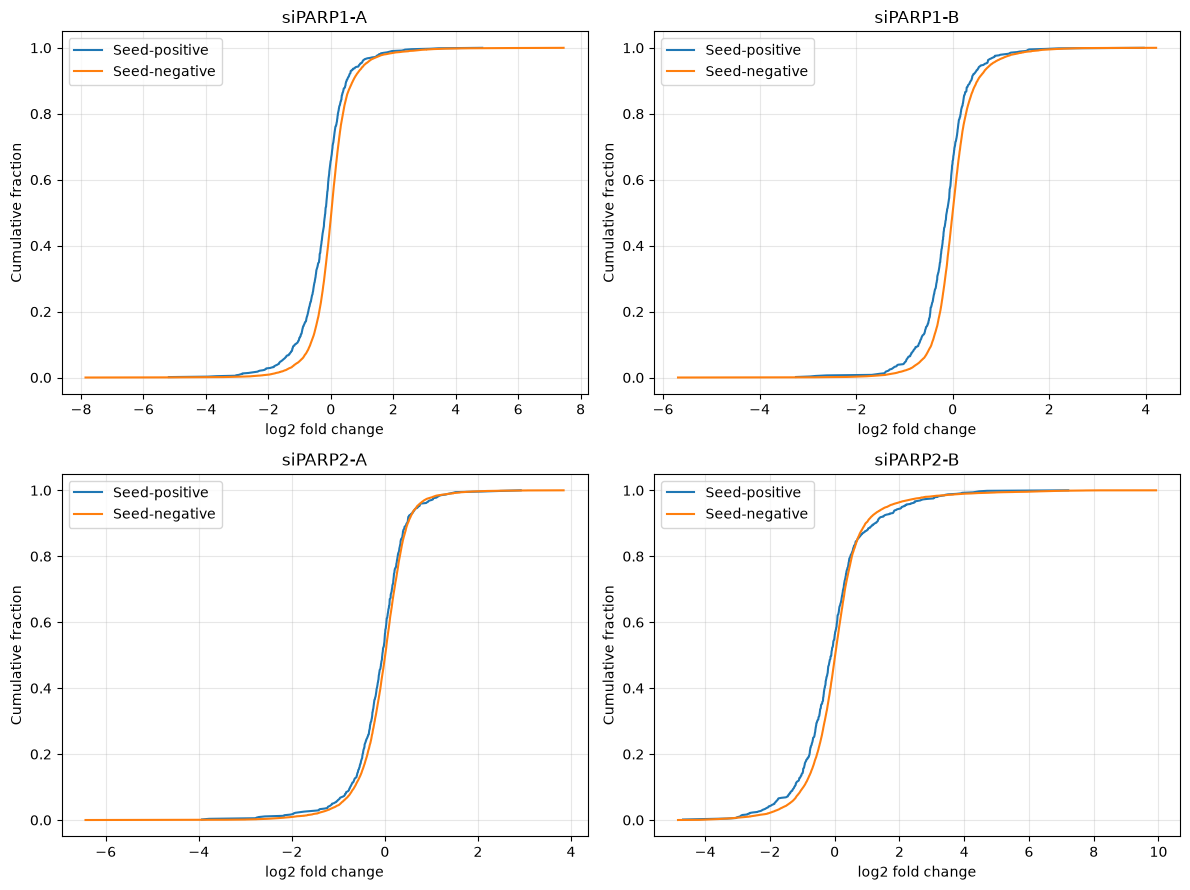

In [38]:
# CDF of filtered data

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, (treatment, df) in zip(axes, sirna_analysis_filtered.items()):

    seed_column = f"{treatment.replace('-', '')}_target_8mer_A1_present"

    positive = df.loc[
        df[seed_column].eq(True), "log2FoldChange"
    ].dropna().sort_values()

    negative = df.loc[
        df[seed_column].eq(False), "log2FoldChange"
    ].dropna().sort_values()

    ax.plot(
        positive,
        np.arange(1, len(positive) + 1) / len(positive),
        label="Seed-positive"
    )

    ax.plot(
        negative,
        np.arange(1, len(negative) + 1) / len(negative),
        label="Seed-negative"
    )

    ax.set_title(treatment)
    ax.set_xlabel("log2 fold change")
    ax.set_ylabel("Cumulative fraction")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

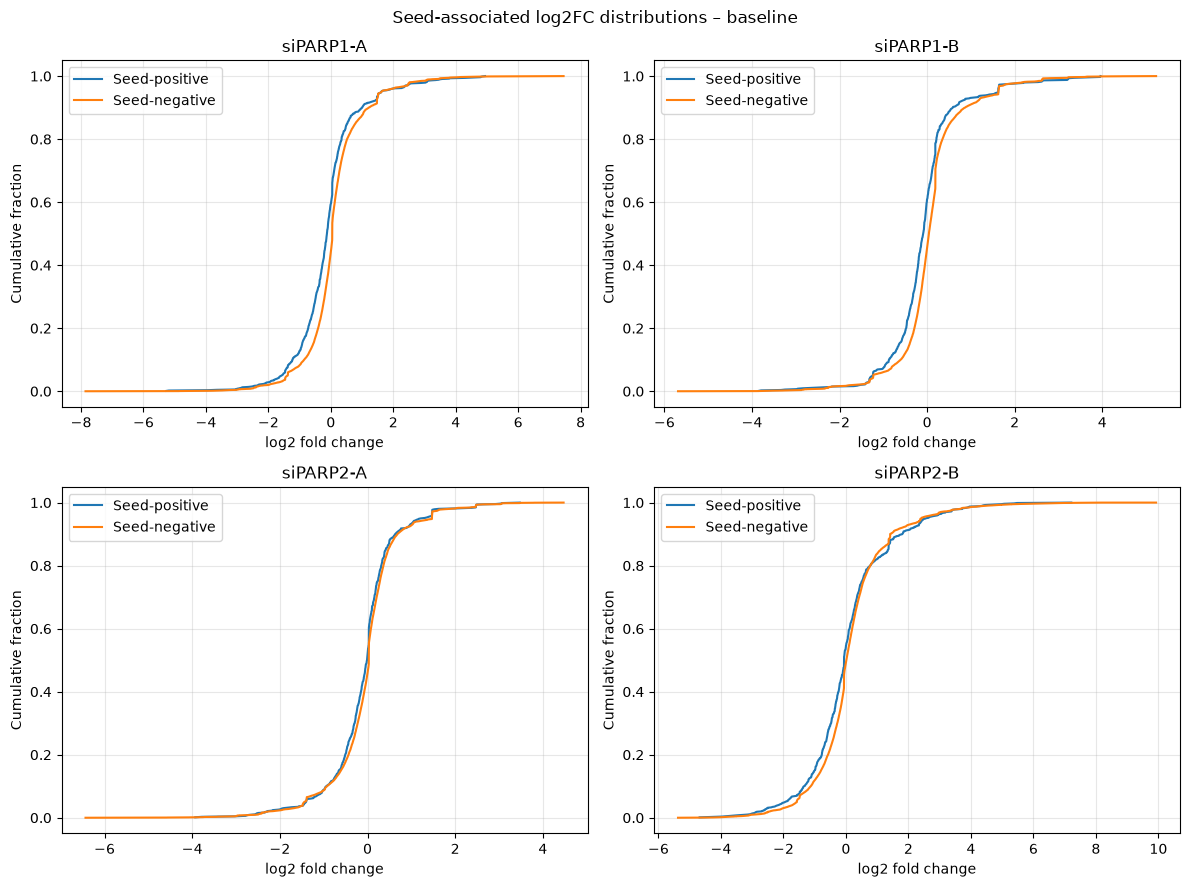

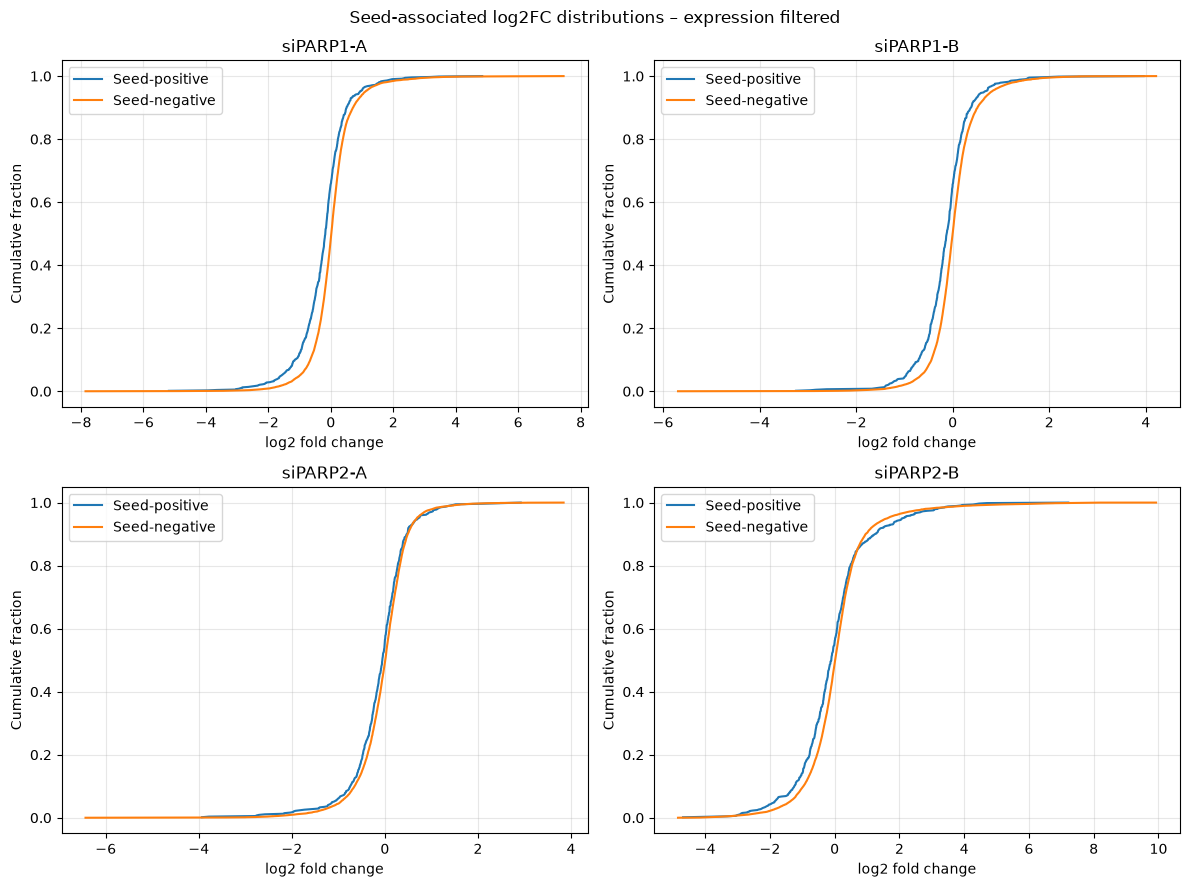

In [39]:
# Save graphs

figures_path = Path("../results/figures")
figures_path.mkdir(parents=True, exist_ok=True)


def plot_seed_cdfs(analysis_data, title):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes = axes.flatten()

    for ax, (treatment, df) in zip(axes, analysis_data.items()):

        seed_column = f"{treatment.replace('-', '')}_target_8mer_A1_present"

        positive = df.loc[
            df[seed_column].eq(True), "log2FoldChange"
        ].dropna().sort_values()

        negative = df.loc[
            df[seed_column].eq(False), "log2FoldChange"
        ].dropna().sort_values()

        ax.plot(
            positive,
            np.arange(1, len(positive) + 1) / len(positive),
            label="Seed-positive"
        )

        ax.plot(
            negative,
            np.arange(1, len(negative) + 1) / len(negative),
            label="Seed-negative"
        )

        ax.set_title(treatment)
        ax.set_xlabel("log2 fold change")
        ax.set_ylabel("Cumulative fraction")
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(title)
    fig.tight_layout()

    return fig


# Baseline
fig_baseline = plot_seed_cdfs(
    sirna_analysis,
    "Seed-associated log2FC distributions – baseline"
)

fig_baseline.savefig(
    figures_path / "GSE114273_CDF_baseline.png",
    dpi=300,
    bbox_inches="tight"
)

# Filtered
fig_filtered = plot_seed_cdfs(
    sirna_analysis_filtered,
    "Seed-associated log2FC distributions – expression filtered"
)

fig_filtered.savefig(
    figures_path / "GSE114273_CDF_filtered.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Summary

- Combined gene-level 3′UTR seed annotations with DESeq2 log2FC results for four siRNA treatments (siPARP1-A/B and siPARP2-A/B).
- Identified seed-positive and seed-negative genes based on the presence of a complementary 8mer-A1 motif in at least one annotated 3′UTR transcript.
- Compared log2FC distributions using cumulative distribution functions (CDFs) and one-sided Mann–Whitney U tests.
- In the baseline analysis, all four siRNAs showed lower median log2FC among seed-positive genes compared with seed-negative genes. All comparisons remained significant after Benjamini–Hochberg FDR correction.
- Performed a sensitivity analysis by retaining genes with raw counts ≥10 in at least two of the ten selected samples. This reduced the analysis population from 16,638 to 12,783 genes per treatment.
- The filtered analysis retained the negative median differences and statistically significant distributional shifts across all four siRNAs after FDR correction.

**Conclusion:** The observed association between 8mer-A1 seed matches and lower gene expression was consistent across all four siRNA treatments and remained evident after excluding low-expression genes. This supports the robustness of the observed association.

**Limitations:** The dataset contains only two biological replicates per condition. 